# Прогноз повітряних тривог (без витоку даних) — Google Colab

**Порядок:** виконуй клітинки зверху вниз. Код проєкту вбудований у розділ 2, окремий архів не потрібен.

Що де зберігається:
- `Google Drive/alerts-forecast/data/raw/` — знімки датасету (кожне завантаження окремо, з міткою часу);
- `Google Drive/alerts-forecast/data/runs/` — результати бектестів;
- SQLite-журнал (`alerts.db`) живе локально в `/content/work` (SQLite на змонтованому Drive буває нестабільним) і копіюється на Drive командою `save_db()`.

Після перезапуску середовища Colab код розділу 2 треба виконати знову (він швидкий).

## 1. Налаштування середовища

In [1]:
import os, sys, shutil, importlib
!pip -q install pytest lightgbm

try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DRIVE = "/content/drive/MyDrive/alerts-forecast"
    IN_COLAB = True
except ImportError:                       # локальний запуск
    WORK_DRIVE = os.path.abspath("alerts-forecast-drive")
    IN_COLAB = False

CODE_DIR  = "/content/alerts-forecast"    # код (ефемерний, відтворюється розділом 2)
LOCAL_DIR = "/content/work"               # локальна SQLite
RAW_DIR   = f"{WORK_DRIVE}/data/raw"
RUNS_DIR  = f"{WORK_DRIVE}/data/runs"
DB_LOCAL  = f"{LOCAL_DIR}/alerts.db"
DB_DRIVE  = f"{WORK_DRIVE}/data/alerts.db"

for d in [RAW_DIR, RUNS_DIR, LOCAL_DIR,
          f"{CODE_DIR}/src/alerts_forecast/sources", f"{CODE_DIR}/src/alerts_forecast/text",
          f"{CODE_DIR}/tests", f"{CODE_DIR}/data"]:
    os.makedirs(d, exist_ok=True)

def restore_db():
    if os.path.exists(DB_DRIVE) and not os.path.exists(DB_LOCAL):
        shutil.copy(DB_DRIVE, DB_LOCAL); print("БД відновлено з Drive")

def save_db():
    shutil.copy(DB_LOCAL, DB_DRIVE); print("БД збережено на Drive:", DB_DRIVE)

restore_db()
print("Colab:", IN_COLAB, "| робоча тека на Drive:", WORK_DRIVE)

Mounted at /content/drive
БД відновлено з Drive
Colab: True | робоча тека на Drive: /content/drive/MyDrive/alerts-forecast


## 2. Код проєкту
Клітинки нижче лише записують модулі у `/content/alerts-forecast`. Читати їх не обов'язково.
Якщо змінюєш модуль вручну — після виконання клітинки перезапусти середовище (**Runtime → Restart session**), інакше Python залишить стару версію в пам'яті.

In [2]:
%%writefile /content/alerts-forecast/src/alerts_forecast/__init__.py
__version__ = "0.1.0"

Writing /content/alerts-forecast/src/alerts_forecast/__init__.py


In [3]:
%%writefile /content/alerts-forecast/src/alerts_forecast/__main__.py
from .cli import main

if __name__ == "__main__":
    main()

Writing /content/alerts-forecast/src/alerts_forecast/__main__.py


In [4]:
%%writefile /content/alerts-forecast/src/alerts_forecast/cli.py
from __future__ import annotations

import argparse
import os

import pandas as pd

from .config import Config
from .store import connect, latest_snapshot, load_messages


def _resolve_csv(args, conn):
    if args.csv:
        return args.csv, None, None
    snap = latest_snapshot(conn)
    if not snap:
        raise SystemExit("Немає знімка. Запусти `fetch` або передай --csv.")
    return snap["path"], snap["fetched_at"], snap["sha256"]


def main(argv=None):
    p = argparse.ArgumentParser(prog="alerts_forecast")
    p.add_argument("--db", default="data/alerts.db")
    sub = p.add_subparsers(dest="cmd", required=True)

    sub.add_parser("fetch", help="завантажити свіжий знімок CSV (Vadimkin)")

    r = sub.add_parser("regions", help="список регіонів/рівнів у CSV")
    r.add_argument("--csv")

    b = sub.add_parser("backtest", help="walk-forward бектест + бойовий прогноз")
    b.add_argument("--csv")
    b.add_argument("--region", required=True)
    b.add_argument("--horizon", type=int, default=6)
    b.add_argument("--target", choices=["start", "any"], default="start")
    b.add_argument("--level", default="oblast")
    b.add_argument("--folds", type=int, default=8)
    b.add_argument("--train-start")
    b.add_argument("--min-train-days", type=int, default=365)
    b.add_argument("--use-messages", action="store_true", help="додати текстові ознаки з таблиці messages")
    b.add_argument("--no-calibrate", action="store_true")
    b.add_argument("--out", default="data/runs")

    po = sub.add_parser("poll", help="живий збір активних тривог alerts.in.ua")
    po.add_argument("--token", default=os.environ.get("ALERTS_IN_UA_TOKEN"))
    po.add_argument("--interval", type=int, default=60)

    im = sub.add_parser("import-messages", help="імпорт повідомлень із JSONL")
    im.add_argument("file")

    sy = sub.add_parser("synthetic", help="згенерувати синтетичний CSV для демо")
    sy.add_argument("--out", default="data/synthetic.csv")

    args = p.parse_args(argv)

    if args.cmd == "synthetic":
        from .synthetic import make_synthetic_csv
        print(make_synthetic_csv(args.out))
        return
    conn = connect(args.db)

    if args.cmd == "fetch":
        from .sources.vadimkin import fetch_snapshot
        print(fetch_snapshot(conn))
    elif args.cmd == "regions":
        from .events import list_regions
        csv, _, _ = _resolve_csv(args, conn)
        print(list_regions(csv).to_string(index=False))
    elif args.cmd == "backtest":
        from .pipeline import run_backtest
        csv, fetched_at, sha = _resolve_csv(args, conn)
        cfg = Config(region=args.region, horizon_hours=args.horizon, target=args.target,
                     level=args.level, n_test_folds=args.folds, train_start=args.train_start,
                     min_train_days=args.min_train_days, calibrate=not args.no_calibrate)
        msgs = load_messages(conn) if args.use_messages else None
        run_backtest(cfg, csv, args.out, fetched_at=fetched_at, snapshot_sha=sha, messages=msgs)
    elif args.cmd == "poll":
        from .sources.alerts_in_ua import poll_loop
        if not args.token:
            raise SystemExit("Потрібен токен: --token або ALERTS_IN_UA_TOKEN")
        poll_loop(conn, args.token, args.interval)
    elif args.cmd == "import-messages":
        from .store import import_messages_jsonl
        print("imported:", import_messages_jsonl(conn, args.file))

Writing /content/alerts-forecast/src/alerts_forecast/cli.py


In [5]:
%%writefile /content/alerts-forecast/src/alerts_forecast/common.py
"""Спільні утиліти. Усі внутрішні часові мітки: tz-aware UTC."""
from __future__ import annotations

import numpy as np
import pandas as pd

KYIV_TZ = "Europe/Kyiv"


def as_ns(x) -> np.ndarray:
    """DatetimeIndex/Series -> numpy datetime64[ns] у UTC (без tz)."""
    idx = pd.DatetimeIndex(x)
    if idx.tz is not None:
        idx = idx.tz_convert("UTC").tz_localize(None)
    return idx.to_numpy().astype("datetime64[ns]")


def minutes_between(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """(a - b) у хвилинах; NaT -> NaN."""
    return (a - b) / np.timedelta64(1, "m")


class LeakageError(RuntimeError):
    """Піднімається, коли тест на усічення виявив доступ до майбутнього."""

Writing /content/alerts-forecast/src/alerts_forecast/common.py


In [6]:
%%writefile /content/alerts-forecast/src/alerts_forecast/config.py
from __future__ import annotations

from dataclasses import asdict, dataclass


@dataclass(frozen=True)
class Config:
    region: str
    horizon_hours: int = 6                 # h: 1..24
    target: str = "start"                  # "start": почнеться нова тривога в (t, t+h]
                                           # "any":   тривога активна хоч у частині (t, t+h]
    lookbacks_hours: tuple = (1, 3, 6, 12, 24, 72, 168)
    level: str | None = "oblast"           # рівень адмін. одиниці (oblast/raion/hromada)
    # --- walk-forward ---
    n_test_folds: int = 8                  # 8 x 7 днів ~ останні 8 тижнів
    test_len_days: int = 7
    min_train_days: int = 365
    train_start: str | None = None         # напр. "2023-01-01" проти дрейфу режиму
    warmup_days: int = 14                  # перші дні без повної історії лагів
    purge_extra_hours: int = 0
    inner_val_days: int = 28               # хвіст train для early stopping + калібрування
    calibrate: bool = True
    # --- дані ---
    asof_lag_hours: int = 1                # відступ від межі покриття датасету
    # --- текст ---
    text_delay_minutes: int = 2
    seed: int = 42
    leak_check_samples: int = 30

    def to_dict(self) -> dict:
        return asdict(self)

Writing /content/alerts-forecast/src/alerts_forecast/config.py


In [7]:
%%writefile /content/alerts-forecast/src/alerts_forecast/cv.py
"""Walk-forward (expanding) з purge: мітки train не перекриваються з тестом."""
from __future__ import annotations

from dataclasses import dataclass

import pandas as pd


@dataclass
class Fold:
    k: int
    train: pd.DatetimeIndex
    test: pd.DatetimeIndex
    test_start: pd.Timestamp     # виключно
    test_end: pd.Timestamp       # включно


def walk_forward(times, horizon_h: int, n_folds: int, test_len_days: int,
                 min_train_days: int, purge_extra_hours: int = 0):
    """`times` — лише ті t, для яких мітка визначена (t+h <= asof)."""
    times = pd.DatetimeIndex(times).sort_values()
    h = pd.Timedelta(hours=horizon_h)
    purge = h + pd.Timedelta(hours=purge_extra_hours)
    test_len = pd.Timedelta(days=test_len_days)
    end = times.max()
    for i, k in enumerate(range(n_folds, 0, -1)):
        test_end = end - (k - 1) * test_len
        test_start = test_end - test_len
        tr = times[times <= test_start - purge]
        te = times[(times > test_start) & (times <= test_end)]
        if len(tr) == 0 or len(te) == 0:
            continue
        if tr.max() - tr.min() < pd.Timedelta(days=min_train_days):
            continue
        # інваріант: вікно мітки останнього train-рядка (tr.max, tr.max+h] закінчується до тесту
        assert tr.max() + h <= test_start, "purge порушено"
        assert tr.max() < te.min()
        yield Fold(i, tr, te, test_start, test_end)

Writing /content/alerts-forecast/src/alerts_forecast/cv.py


In [8]:
%%writefile /content/alerts-forecast/src/alerts_forecast/events.py
"""Завантаження та нормалізація подій тривог (CSV Vadimkin-формату)."""
from __future__ import annotations

from dataclasses import dataclass

import pandas as pd

from .common import KYIV_TZ

START_COLS = ("started_at", "start", "started")
END_COLS = ("finished_at", "finish", "finished", "end", "ended_at")
REGION_COLS = ("oblast", "region", "location_oblast", "location_title")


@dataclass
class Events:
    events: pd.DataFrame          # started_at, finished_at (UTC, finished_at може бути NaT)
    asof: pd.Timestamp            # межа покриття даних (UTC, кругла година)
    region_name: str
    n_dropped: int


def _first(cols, candidates, what):
    for c in candidates:
        if c in cols:
            return c
    raise KeyError(f"Не знайдено колонку для «{what}». Є: {list(cols)}")


def parse_ts(s: pd.Series) -> pd.Series:
    """Рядки -> UTC. Якщо є офсет — довіряємо йому; якщо ні — вважаємо київським часом."""
    s = s.astype("object").where(s.notna(), None)
    sample = s.dropna().astype(str)
    has_tz = len(sample) > 0 and sample.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$", regex=True).mean() > 0.5
    if has_tz:
        return pd.to_datetime(s, utc=True, errors="coerce", format="mixed")
    out = pd.to_datetime(s, errors="coerce")
    # ambiguous=False: неоднозначна година при переході на зимовий час -> зимовий. Помилка ≤ 1 год у 1 годині на рік.
    return out.dt.tz_localize(KYIV_TZ, ambiguous=False, nonexistent="shift_forward").dt.tz_convert("UTC")


def read_raw(csv_path) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    df.columns = [c.strip().lower() for c in df.columns]
    return df


def list_regions(csv_path) -> pd.DataFrame:
    df = read_raw(csv_path)
    rc = _first(df.columns, REGION_COLS, "регіон")
    keys = [rc] + (["level"] if "level" in df.columns else [])
    return df.groupby(keys).size().rename("n_alerts").reset_index()


def load_events(csv_path, region: str, level: str | None = "oblast",
                fetched_at: pd.Timestamp | None = None, asof_lag_hours: int = 1) -> Events:
    df = read_raw(csv_path)
    sc = _first(df.columns, START_COLS, "початок")
    ec = _first(df.columns, END_COLS, "кінець")
    rc = _first(df.columns, REGION_COLS, "регіон")
    df["_s"], df["_e"] = parse_ts(df[sc]), parse_ts(df[ec])

    # Межа покриття: максимум за ВСІМА регіонами (по одному регіону «тиша» ≠ «даних ще нема»),
    # не пізніше моменту завантаження знімка.
    cover = max(df["_s"].max(), df["_e"].max())
    if fetched_at is not None:
        cover = min(cover, pd.Timestamp(fetched_at))
    asof = (cover - pd.Timedelta(hours=asof_lag_hours)).floor("h")

    if level and "level" in df.columns:
        sub = df[df["level"].astype(str).str.lower() == level.lower()]
        if sub.empty:
            raise ValueError(f"Рівень «{level}» не знайдено. Є: {sorted(df['level'].astype(str).unique())}")
        df = sub
    names = df[rc].astype(str)
    exact = names[names.str.lower() == region.lower()].unique()
    cand = exact if len(exact) else names[names.str.contains(region, case=False, regex=False)].unique()
    if len(cand) != 1:
        raise ValueError(f"Регіон «{region}»: збігів {len(cand)} -> {list(cand)[:15]}. "
                         f"Уточни назву (див. команду `regions`).")
    region_name = str(cand[0])
    ev = df.loc[names == region_name, ["_s", "_e"]].rename(columns={"_s": "started_at", "_e": "finished_at"})

    n0 = len(ev)
    ev = ev.dropna(subset=["started_at"])
    ev = ev[ev["finished_at"].isna() | (ev["finished_at"] >= ev["started_at"])]
    ev = ev.drop_duplicates().sort_values("started_at").reset_index(drop=True)
    return Events(ev, asof, region_name, n0 - len(ev))

Writing /content/alerts-forecast/src/alerts_forecast/events.py


In [9]:
%%writefile /content/alerts-forecast/src/alerts_forecast/features.py
"""Ознаки X(t) — суворо as-of: лише події з started_at <= t та finished_at <= t.

Жодного shift(-k), center=True, bfill, interpolate. Єдине місце, де дозволено
дивитись уперед, — labels.py."""
from __future__ import annotations

import numpy as np
import pandas as pd

from .common import KYIV_TZ, as_ns, minutes_between

DEFAULT_LOOKBACKS = (1, 3, 6, 12, 24, 72, 168)
_ORIGIN = np.datetime64("2020-01-01T00:00:00", "ns")


def make_grid(first_start: pd.Timestamp, asof: pd.Timestamp) -> pd.DatetimeIndex:
    start = first_start.ceil("h") - pd.Timedelta(hours=1)
    return pd.date_range(start, asof.floor("h"), freq="h", tz="UTC")


def start_counts(events: pd.DataFrame, index: pd.DatetimeIndex) -> pd.Series:
    """Кількість стартів у (t-1h, t] для кожного t ∈ index."""
    bins = events["started_at"].dt.ceil("h")
    return bins.groupby(bins).size().reindex(index, fill_value=0).astype(float)


def _prep(events: pd.DataFrame):
    s = np.sort(as_ns(events["started_at"]))
    fin = np.sort(as_ns(events["finished_at"].dropna()))   # відомі кінці; NaT = «ще триває»
    return s, fin


def _min_since(sorted_arr: np.ndarray, n_le: np.ndarray, g: np.ndarray) -> np.ndarray:
    pad = np.concatenate([np.array(["NaT"], dtype="datetime64[ns]"), sorted_arr])
    return minutes_between(g, pad[n_le])


def _alert_minutes_cum(s, fin, t: np.ndarray) -> np.ndarray:
    """F(t) = Σ_e max(0, min(finish_e, t) − start_e), хвилини. Використовує лише
    старти <= t та кінці <= t (префіксні суми по відсортованих масивах)."""
    def m(a):
        return (a - _ORIGIN) / np.timedelta64(1, "m")
    s_m, f_m, t_m = m(s), m(fin), m(t)
    cs = np.concatenate([[0.0], np.cumsum(s_m)])
    cf = np.concatenate([[0.0], np.cumsum(f_m)])
    ns = np.searchsorted(s, t, side="right")
    nf = np.searchsorted(fin, t, side="right")
    return (ns * t_m - cs[ns]) - (nf * t_m - cf[nf])


def active_now(events: pd.DataFrame, grid: pd.DatetimeIndex) -> pd.Series:
    s, fin = _prep(events)
    g = as_ns(grid)
    n = np.searchsorted(s, g, side="right") - np.searchsorted(fin, g, side="right")
    return pd.Series(n, index=grid, name="n_active")


def _lagged_window_count(counts: pd.Series, lag_h: int, h: int) -> pd.Series:
    """Σ_{j=1..h} counts[t − lag_h + j] = старти у (t−lag_h, t−lag_h+h].
    Усі зсуви невід'ємні (lag_h >= h), тобто тільки минуле/теперішнє."""
    assert lag_h >= h
    parts = [counts.shift(lag_h - j) for j in range(1, h + 1)]
    return pd.concat(parts, axis=1).sum(axis=1, min_count=h)


def build_features(events: pd.DataFrame, grid: pd.DatetimeIndex, horizon_h: int,
                   lookbacks=DEFAULT_LOOKBACKS) -> pd.DataFrame:
    if not 1 <= horizon_h <= 24:
        raise ValueError("horizon_h має бути 1..24 (сезонні лаги будуються з кроком 24 год)")
    s, fin = _prep(events)
    g = as_ns(grid)
    ns = np.searchsorted(s, g, side="right")
    nf = np.searchsorted(fin, g, side="right")

    X = pd.DataFrame(index=grid)
    X["n_active"] = (ns - nf).astype(float)
    X["is_active_now"] = (X["n_active"] > 0).astype(float)
    X["mins_since_last_start"] = _min_since(s, ns, g)
    X["mins_since_last_end"] = _min_since(fin, nf, g)

    counts = start_counts(events, grid)
    F_now = _alert_minutes_cum(s, fin, g)
    for k in lookbacks:
        X[f"n_starts_{k}h"] = counts.rolling(k, min_periods=1).sum()
        F_prev = _alert_minutes_cum(s, fin, g - np.timedelta64(k, "h"))
        X[f"alert_frac_{k}h"] = np.clip((F_now - F_prev) / (60.0 * k), 0.0, 1.0)

    # «У цьому ж вікні (t, t+h] N днів тому була тривога?» — сезонність атак без дивіться-вперед.
    ind = {}
    for d in range(1, 8):
        w = _lagged_window_count(counts, 24 * d, horizon_h)
        ind[d] = (w > 0).astype(float).where(w.notna())
    X["same_win_1d"] = ind[1]
    X["same_win_7d_mean"] = pd.concat(ind.values(), axis=1).mean(axis=1)

    # Календар (відомий наперед), київський час
    loc = grid.tz_convert(KYIV_TZ)
    X["hour"] = loc.hour.astype(float)
    X["dow"] = loc.dayofweek.astype(float)
    X["month"] = loc.month.astype(float)
    X["hour_sin"] = np.sin(2 * np.pi * loc.hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * loc.hour / 24)
    return X

Writing /content/alerts-forecast/src/alerts_forecast/features.py


In [10]:
%%writefile /content/alerts-forecast/src/alerts_forecast/labels.py
"""Мітки y(t, h). ЄДИНЕ місце проєкту, де дозволено дивитись у майбутнє.

target="start": 1, якщо нова тривога ПОЧНЕТЬСЯ в (t, t+h]
target="any":   1, якщо тривога активна хоч у частині (t, t+h] (враховує вже активну на t)
Рядки, де t+h > asof (вікно виходить за межу покриття даних), отримують NaN."""
from __future__ import annotations

import numpy as np
import pandas as pd

from .features import active_now, start_counts


def build_labels(events: pd.DataFrame, grid: pd.DatetimeIndex, horizon_h: int,
                 target: str, asof: pd.Timestamp) -> pd.Series:
    if target not in ("start", "any"):
        raise ValueError("target: 'start' | 'any'")
    ext = pd.date_range(grid[0], grid[-1] + pd.Timedelta(hours=horizon_h), freq="h", tz="UTC")
    counts = start_counts(events, ext)
    fwd = pd.concat([counts.shift(-j) for j in range(1, horizon_h + 1)], axis=1) \
            .sum(axis=1, min_count=horizon_h).reindex(grid)          # <- look-ahead
    y = (fwd > 0)
    if target == "any":
        y = y | (active_now(events, grid) > 0)
    y = y.astype(float)
    y[grid + pd.Timedelta(hours=horizon_h) > asof] = np.nan
    return y.rename("y")

Writing /content/alerts-forecast/src/alerts_forecast/labels.py


In [11]:
%%writefile /content/alerts-forecast/src/alerts_forecast/leakcheck.py
"""Тест на інваріантність до усічення: ознаки в момент t на повних даних мають
збігатися з ознаками на даних, обрізаних до того, що було відомо на t."""
from __future__ import annotations

from typing import Callable

import numpy as np
import pandas as pd

from .common import LeakageError


def truncate_events(events: pd.DataFrame, t: pd.Timestamp) -> pd.DataFrame:
    e = events[events["started_at"] <= t].copy()
    e.loc[e["finished_at"] > t, "finished_at"] = pd.NaT       # кінець ще невідомий
    return e


def check_truncation_invariance(build: Callable[[object, pd.DatetimeIndex], pd.DataFrame],
                                truncate: Callable[[object, pd.Timestamp | None], object],
                                data, grid: pd.DatetimeIndex, times,
                                rtol: float = 1e-9, atol: float = 1e-7) -> dict:
    """build(view, grid) -> DataFrame; truncate(data, t) -> дані «як відомо на t» (t=None -> усе).
    Повертає {t: [колонки з витоком]}; порожній dict = витоку не знайдено."""
    full = build(truncate(data, None), grid)
    leaks: dict = {}
    for t in times:
        part = build(truncate(data, t), grid[grid <= t])
        a, b = full.loc[t], part.loc[t]
        ok = np.isclose(a.values.astype(float), b.values.astype(float),
                        rtol=rtol, atol=atol, equal_nan=True)
        if not ok.all():
            leaks[t] = list(full.columns[~ok])
    return leaks


def assert_no_leakage(*args, **kwargs) -> None:
    leaks = check_truncation_invariance(*args, **kwargs)
    if leaks:
        t0 = next(iter(leaks))
        cols = sorted({c for v in leaks.values() for c in v})
        raise LeakageError(f"Витік у {len(leaks)} моментах (напр. {t0}); колонки: {cols}")

Writing /content/alerts-forecast/src/alerts_forecast/leakcheck.py


In [12]:
%%writefile /content/alerts-forecast/src/alerts_forecast/metrics.py
from __future__ import annotations

import numpy as np
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve


def recall_at_fpr(y, p, fpr_target: float = 0.05) -> float:
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(fpr_target, fpr, tpr))


def ece(y, p, bins: int = 10) -> float:
    y, p = np.asarray(y, float), np.asarray(p, float)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    tot = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(tot)


def evaluate(y, p, base_rate_train: float) -> dict:
    y, p = np.asarray(y, float), np.asarray(p, float)
    out = {"n": len(y), "prevalence": float(y.mean()),
           "brier": float(brier_score_loss(y, p))}
    ref = brier_score_loss(y, np.full_like(y, base_rate_train))
    out["bss_vs_base_rate"] = float(1 - out["brier"] / ref) if ref > 0 else np.nan
    if 0 < y.sum() < len(y):
        out["pr_auc"] = float(average_precision_score(y, p))
        out["roc_auc"] = float(roc_auc_score(y, p))
        out["recall@fpr5%"] = recall_at_fpr(y, p, 0.05)
    else:
        out["pr_auc"] = out["roc_auc"] = out["recall@fpr5%"] = np.nan
    out["ece"] = ece(y, p)
    return out

Writing /content/alerts-forecast/src/alerts_forecast/metrics.py


In [13]:
%%writefile /content/alerts-forecast/src/alerts_forecast/models.py
"""Бейзлайни (фітяться лише на train) і GBM (LightGBM, а за його відсутності sklearn HGB).
Early stopping і калібрування — лише на хвості train, що ПІСЛЯ fit-частини (з purge)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import log_loss

try:
    import lightgbm as lgb
    HAVE_LGBM = True
except Exception:  # noqa: BLE001
    HAVE_LGBM = False
from sklearn.ensemble import HistGradientBoostingClassifier


def split_inner(train_times: pd.DatetimeIndex, horizon_h: int, val_days: int):
    """fit | purge(h) | val — усе в межах train, у хронологічному порядку."""
    val_start = train_times.max() - pd.Timedelta(days=val_days)
    fit = train_times[train_times <= val_start - pd.Timedelta(hours=horizon_h)]
    val = train_times[train_times > val_start]
    return fit, val


# ---------------- бейзлайни ----------------
class BaseRate:
    name = "base_rate"

    def fit(self, X, y):
        self.p = float(y.mean())
        return self

    def predict(self, X):
        return np.full(len(X), self.p)


class PersistenceCalibrated:
    """P(y | були старти за останні k годин), оцінено на train."""
    name = "persistence"

    def __init__(self, col: str):
        self.col = col

    def fit(self, X, y):
        flag = X[self.col].to_numpy() > 0
        self.p1 = float(y[flag].mean()) if flag.any() else float(y.mean())
        self.p0 = float(y[~flag].mean()) if (~flag).any() else float(y.mean())
        return self

    def predict(self, X):
        return np.where(X[self.col].to_numpy() > 0, self.p1, self.p0)


class HourDowFreq:
    """Кліматологія за (година, день тижня) зі зглажуванням до base rate."""
    name = "hour_dow_freq"

    def __init__(self, shrink: float = 20.0):
        self.m = shrink

    def fit(self, X, y):
        self.base = float(y.mean())
        df = pd.DataFrame({"h": X["hour"].to_numpy(), "d": X["dow"].to_numpy(), "y": y.to_numpy()})
        g = df.groupby(["h", "d"]).y.agg(["sum", "count"])
        self.tab = ((g["sum"] + self.m * self.base) / (g["count"] + self.m)).to_dict()
        return self

    def predict(self, X):
        return np.array([self.tab.get((h, d), self.base)
                         for h, d in zip(X["hour"].to_numpy(), X["dow"].to_numpy())])


def make_baselines(lookbacks, horizon_h):
    k = max([k for k in lookbacks if k <= horizon_h] or [min(lookbacks)])
    return [BaseRate(), PersistenceCalibrated(f"n_starts_{k}h"), HourDowFreq()]


# ---------------- GBM ----------------
class GBM:
    name = "gbm"

    def __init__(self, seed: int = 42, calibrate: bool = True):
        self.seed, self.calibrate = seed, calibrate
        self.backend = "lightgbm" if HAVE_LGBM else "sklearn_hgb"

    def _raw(self, X):
        if self.const is not None:
            return np.full(len(X), self.const)
        if self.backend == "lightgbm":
            return self.m.predict_proba(X)[:, 1]
        for i, p in enumerate(self.m.staged_predict_proba(X)):
            if i + 1 == self.best_iter:
                return p[:, 1]
        return p[:, 1]

    def fit(self, Xf, yf, Xv, yv):
        self.const, self.iso = None, None
        if yf.nunique() < 2:
            self.const = float(yf.mean())
            return self
        if self.backend == "lightgbm":
            self.m = lgb.LGBMClassifier(
                n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                random_state=self.seed, verbose=-1)
            self.m.fit(Xf, yf, eval_set=[(Xv, yv)], eval_metric="binary_logloss",
                       callbacks=[lgb.early_stopping(100, verbose=False)])
        else:
            # early_stopping=False: вбудований варіант робить ВИПАДКОВИЙ split = витік у часі.
            self.m = HistGradientBoostingClassifier(
                learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=50,
                l2_regularization=1.0, early_stopping=False, random_state=self.seed).fit(Xf, yf)
            losses = [log_loss(yv, np.clip(p[:, 1], 1e-6, 1 - 1e-6), labels=[0, 1])
                      for p in self.m.staged_predict_proba(Xv)]
            self.best_iter = int(np.argmin(losses)) + 1
        if self.calibrate and yv.nunique() == 2:
            self.iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0) \
                .fit(self._raw(Xv), yv)
        return self

    def predict(self, X):
        p = self._raw(X)
        return self.iso.predict(p) if self.iso is not None else p

Writing /content/alerts-forecast/src/alerts_forecast/models.py


In [14]:
%%writefile /content/alerts-forecast/src/alerts_forecast/pipeline.py
"""Оркестрація: дані -> ознаки/мітки -> тест на витік -> walk-forward -> метрики -> прогноз."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from .common import LeakageError
from .config import Config
from .cv import walk_forward
from .events import load_events
from .features import build_features, make_grid
from .labels import build_labels
from .leakcheck import assert_no_leakage, truncate_events
from .metrics import evaluate
from .models import GBM, make_baselines, split_inner
from .text.features import text_features, truncate_messages


def _builders(cfg: Config, messages):
    """build(view, grid) і truncate(view, t) для events (+ опційно messages)."""
    if messages is None:
        def build(view, grid):
            return build_features(view, grid, cfg.horizon_hours, cfg.lookbacks_hours)

        def truncate(data, t):
            return data if t is None else truncate_events(data, t)
        return build, truncate

    def build(view, grid):
        ev, ms = view
        X = build_features(ev, grid, cfg.horizon_hours, cfg.lookbacks_hours)
        return X.join(text_features(ms, grid, cfg.text_delay_minutes))

    def truncate(data, t):
        ev, ms = data
        return data if t is None else (truncate_events(ev, t),
                                       truncate_messages(ms, t, cfg.text_delay_minutes))
    return build, truncate


def run_backtest(cfg: Config, csv_path, out_dir="data/runs", fetched_at=None,
                 snapshot_sha=None, messages: pd.DataFrame | None = None,
                 events_override=None, verbose=True) -> dict:
    ev = events_override or load_events(csv_path, cfg.region, cfg.level, fetched_at, cfg.asof_lag_hours)
    events, asof = ev.events, ev.asof
    if verbose:
        print(f"Регіон: {ev.region_name} | подій: {len(events)} (відкинуто {ev.n_dropped}) | "
              f"покриття даних до {asof}")

    grid = make_grid(events["started_at"].min(), asof)
    build, truncate = _builders(cfg, messages)
    data = events if messages is None else (events, messages)
    X = build(data, grid)
    y = build_labels(events, grid, cfg.horizon_hours, cfg.target, asof)

    ok = y.notna() & (grid >= grid[0] + pd.Timedelta(days=cfg.warmup_days))
    if cfg.train_start:
        ok &= grid >= pd.Timestamp(cfg.train_start, tz="UTC")
    labeled_times = grid[ok.to_numpy()]

    # ---- 1) автоматичний тест на витік ПЕРЕД будь-яким навчанням ----
    rng = np.random.default_rng(cfg.seed)
    pool = labeled_times[len(labeled_times) // 10:]
    sample = list(rng.choice(pool, size=min(cfg.leak_check_samples, len(pool)), replace=False))
    sample = [pd.Timestamp(t, tz="UTC") if pd.Timestamp(t).tzinfo is None else pd.Timestamp(t)
              for t in sample] + [grid[-1]]
    assert_no_leakage(build, truncate, data, grid, sample)
    if verbose:
        print(f"Тест на усічення: OK ({len(sample)} моментів)")

    # ---- 2) walk-forward ----
    feat_cols = list(X.columns)
    rows, preds = [], []
    folds = list(walk_forward(labeled_times, cfg.horizon_hours, cfg.n_test_folds, cfg.test_len_days,
                              cfg.min_train_days, cfg.purge_extra_hours))
    if not folds:
        raise RuntimeError("Жодного фолда: замало даних для min_train_days / n_test_folds.")
    for f in folds:
        fit_t, val_t = split_inner(f.train, cfg.horizon_hours, cfg.inner_val_days)
        Xtr, ytr = X.loc[f.train], y.loc[f.train]
        Xte, yte = X.loc[f.test], y.loc[f.test]
        models = make_baselines(cfg.lookbacks_hours, cfg.horizon_hours)
        out = pd.DataFrame({"t": f.test, "fold": f.k, "y": yte.to_numpy()})
        for m in models:
            m.fit(Xtr, ytr)
            out[m.name] = m.predict(Xte)
        gbm = GBM(cfg.seed, cfg.calibrate).fit(X.loc[fit_t], y.loc[fit_t], X.loc[val_t], y.loc[val_t])
        out["gbm"] = gbm.predict(Xte)
        preds.append(out)
        base = float(ytr.mean())
        for name in ["base_rate", "persistence", "hour_dow_freq", "gbm"]:
            r = evaluate(out["y"], out[name], base)
            rows.append({"fold": f.k, "test_from": f.test.min(), "test_to": f.test.max(),
                         "model": name, **r})
    metrics = pd.DataFrame(rows)
    preds = pd.concat(preds, ignore_index=True)
    base_all = float(y.loc[folds[0].train].mean())
    pooled = pd.DataFrame([{"model": n, **evaluate(preds["y"], preds[n], base_all)}
                           for n in ["base_rate", "persistence", "hour_dow_freq", "gbm"]])

    # ---- 3) бойовий прогноз на останню годину (мітки для неї ще не існують) ----
    all_t = labeled_times
    fit_t, val_t = split_inner(all_t, cfg.horizon_hours, cfg.inner_val_days)
    final = GBM(cfg.seed, cfg.calibrate).fit(X.loc[fit_t], y.loc[fit_t], X.loc[val_t], y.loc[val_t])
    t_now = grid[-1]
    forecast = {"made_at": str(t_now), "window": f"({t_now}, {t_now + pd.Timedelta(hours=cfg.horizon_hours)}]",
                "p_gbm": float(final.predict(X.loc[[t_now]])[0]), "backend": final.backend}

    out_dir = Path(out_dir) / f"{ev.region_name.replace(' ', '_')}_h{cfg.horizon_hours}_{cfg.target}"
    out_dir.mkdir(parents=True, exist_ok=True)
    metrics.to_csv(out_dir / "metrics_by_fold.csv", index=False)
    pooled.to_csv(out_dir / "metrics_pooled.csv", index=False)
    preds.to_csv(out_dir / "predictions.csv", index=False)
    (out_dir / "manifest.json").write_text(json.dumps({
        "config": cfg.to_dict(), "region_resolved": ev.region_name, "asof": str(asof),
        "n_events": len(events), "snapshot_sha256": snapshot_sha,
        "features": feat_cols, "n_folds": len(folds), "gbm_backend": final.backend,
        "forecast": forecast}, ensure_ascii=False, indent=2, default=str))

    if verbose:
        pd.set_option("display.width", 200)
        print(f"\nФолдів: {len(folds)} | тест: {folds[0].test.min()} … {folds[-1].test.max()}")
        print("\nПідсумок по всіх тестових фолдах (pooled):")
        print(pooled.round(4).to_string(index=False))
        print("\nОстанній фолд:")
        last = metrics[metrics.fold == folds[-1].k].drop(columns=["test_from", "test_to"])
        print(last.round(4).to_string(index=False))
        print(f"\nПрогноз: {forecast}\nРезультати: {out_dir}")
    return {"metrics": metrics, "pooled": pooled, "preds": preds, "forecast": forecast,
            "out_dir": out_dir}

Writing /content/alerts-forecast/src/alerts_forecast/pipeline.py


In [15]:
%%writefile /content/alerts-forecast/src/alerts_forecast/sources/__init__.py
# (порожній файл)

Writing /content/alerts-forecast/src/alerts_forecast/sources/__init__.py


In [16]:
%%writefile /content/alerts-forecast/src/alerts_forecast/sources/alerts_in_ua.py
"""Живий збір активних тривог з alerts.in.ua (потрібен токен API).
Пишемо в append-only журнал із observed_at: це єдиний спосіб отримати
справжній as-of для майбутніх бектестів (включно з ревізіями записів).

УВАГА: назви полів відповіді тут написані за пам'яттю про v3 API — звір із
документацією alerts.in.ua і перевір ліміти запитів перед запуском циклу."""
from __future__ import annotations

import json
import time
import urllib.request

import pandas as pd

from ..store import utcnow

API_ACTIVE = "https://api.alerts.in.ua/v3/alerts/active.json"


def fetch_active(token: str, timeout: int = 20) -> list[dict]:
    req = urllib.request.Request(API_ACTIVE, headers={"Authorization": f"Bearer {token}"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.loads(resp.read().decode("utf-8")).get("alerts", [])


def record_poll(conn, alerts: list[dict], now: pd.Timestamp | None = None) -> dict:
    """Записує зміни стану. Окремо тестується без мережі."""
    now = now or utcnow()
    latest = {r[0]: (r[1], r[2]) for r in conn.execute(
        "SELECT alert_id, finished_at, updated_at FROM alert_observations "
        "WHERE obs_id IN (SELECT MAX(obs_id) FROM alert_observations GROUP BY alert_id)")}
    seen, n_new, n_end = set(), 0, 0
    for a in alerts:
        aid = str(a.get("id"))
        seen.add(aid)
        state = (a.get("finished_at"), a.get("updated_at"))
        if latest.get(aid) == state:
            continue
        conn.execute(
            "INSERT INTO alert_observations(observed_at,alert_id,location_title,location_type,"
            "location_oblast,alert_type,started_at,finished_at,updated_at,note) VALUES(?,?,?,?,?,?,?,?,?,?)",
            (now.isoformat(), aid, a.get("location_title"), a.get("location_type"),
             a.get("location_oblast"), a.get("alert_type"), a.get("started_at"),
             a.get("finished_at"), a.get("updated_at"), None))
        n_new += 1
    # тривога зникла з active -> кінець не пізніше за поточний опитування
    for aid, (fin, _) in latest.items():
        if fin is None and aid not in seen:
            prev = conn.execute(
                "SELECT location_title,location_type,location_oblast,alert_type,started_at "
                "FROM alert_observations WHERE alert_id=? ORDER BY obs_id DESC LIMIT 1",
                (aid,)).fetchone()
            conn.execute(
                "INSERT INTO alert_observations(observed_at,alert_id,location_title,location_type,"
                "location_oblast,alert_type,started_at,finished_at,updated_at,note) VALUES(?,?,?,?,?,?,?,?,?,?)",
                (now.isoformat(), aid, *prev, now.isoformat(), None, "inferred_end"))
            n_end += 1
    conn.commit()
    return {"new_or_changed": n_new, "inferred_ends": n_end}


def poll_loop(conn, token: str, interval_s: int = 60):
    while True:
        try:
            print(time.strftime("%H:%M:%S"), record_poll(conn, fetch_active(token)), flush=True)
        except Exception as e:  # noqa: BLE001
            print("poll error:", e, flush=True)
        time.sleep(interval_s)

Writing /content/alerts-forecast/src/alerts_forecast/sources/alerts_in_ua.py


In [17]:
%%writefile /content/alerts-forecast/src/alerts_forecast/sources/vadimkin.py
"""Знімки CSV Vadimkin/ukrainian-air-raid-sirens-dataset (datasets/official_data_en.csv).
Кожне завантаження зберігається окремою теку з міткою часу + реєструється у SQLite."""
from __future__ import annotations

import urllib.request
from pathlib import Path

import pandas as pd

from ..store import register_snapshot, utcnow

REPO = "Vadimkin/ukrainian-air-raid-sirens-dataset"
FILE = "datasets/official_data_en.csv"
# Назву гілки перевір сам: пробуємо обидві поширені.
URLS = [f"https://raw.githubusercontent.com/{REPO}/{b}/{FILE}" for b in ("main", "master")]


def fetch_snapshot(conn, raw_dir: str | Path = "data/raw", timeout: int = 120) -> dict:
    fetched_at = utcnow()
    last_err = None
    for url in URLS:
        try:
            with urllib.request.urlopen(url, timeout=timeout) as resp:
                payload = resp.read()
            break
        except Exception as e:  # noqa: BLE001
            last_err = e
    else:
        raise RuntimeError(f"Не вдалося завантажити датасет ({last_err}). "
                           f"Склонуй репозиторій вручну і передай --csv.")
    d = Path(raw_dir) / fetched_at.strftime("%Y%m%dT%H%M%SZ")
    d.mkdir(parents=True, exist_ok=True)
    path = d / "official_data_en.csv"
    path.write_bytes(payload)
    n_rows = max(payload.count(b"\n") - 1, 0)
    info = register_snapshot(conn, "vadimkin", path, fetched_at, n_rows)
    if not info["new"]:
        path.unlink(missing_ok=True)
        d.rmdir()
    return info

Writing /content/alerts-forecast/src/alerts_forecast/sources/vadimkin.py


In [18]:
%%writefile /content/alerts-forecast/src/alerts_forecast/store.py
"""SQLite-сховище: індекс знімків датасету, append-only журнал живих спостережень
(alerts.in.ua) і журнал текстових повідомлень. Усе, що пишеться, має ingested_at."""
from __future__ import annotations

import hashlib
import json
import sqlite3
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

SCHEMA = """
CREATE TABLE IF NOT EXISTS snapshots(
  snapshot_id INTEGER PRIMARY KEY AUTOINCREMENT,
  source      TEXT NOT NULL,
  fetched_at  TEXT NOT NULL,
  sha256      TEXT NOT NULL,
  path        TEXT NOT NULL,
  n_rows      INTEGER,
  UNIQUE(source, sha256)
);
CREATE TABLE IF NOT EXISTS alert_observations(
  obs_id      INTEGER PRIMARY KEY AUTOINCREMENT,
  observed_at TEXT NOT NULL,           -- коли МИ це побачили (справжній as-of)
  alert_id    TEXT NOT NULL,
  location_title TEXT, location_type TEXT, location_oblast TEXT,
  alert_type  TEXT,
  started_at  TEXT, finished_at TEXT, updated_at TEXT,
  note        TEXT
);
CREATE INDEX IF NOT EXISTS ix_obs_alert ON alert_observations(alert_id);
CREATE TABLE IF NOT EXISTS messages(
  channel TEXT NOT NULL, msg_id INTEGER NOT NULL, version INTEGER NOT NULL DEFAULT 1,
  text TEXT,
  published_at TEXT NOT NULL,
  version_available_at TEXT NOT NULL,  -- коли саме ця версія тексту була в нашому розпорядженні
  ingested_at TEXT NOT NULL,
  backfilled INTEGER NOT NULL,         -- 1 = історичний експорт (ingested_at не відображає реальність)
  is_edited INTEGER NOT NULL DEFAULT 0,
  PRIMARY KEY(channel, msg_id, version)
);
"""


def utcnow() -> pd.Timestamp:
    return pd.Timestamp(datetime.now(timezone.utc))


def connect(path: str | Path) -> sqlite3.Connection:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    conn = sqlite3.connect(str(path))
    conn.executescript(SCHEMA)
    return conn


def sha256_file(path: str | Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# ---------------- знімки ----------------
def register_snapshot(conn, source, path, fetched_at, n_rows=None) -> dict:
    sha = sha256_file(path)
    row = conn.execute(
        "SELECT snapshot_id, fetched_at, path FROM snapshots WHERE source=? AND sha256=?",
        (source, sha)).fetchone()
    if row:  # байт-в-байт той самий файл вже є
        return {"snapshot_id": row[0], "fetched_at": pd.Timestamp(row[1]), "path": row[2],
                "sha256": sha, "new": False}
    conn.execute("INSERT INTO snapshots(source,fetched_at,sha256,path,n_rows) VALUES(?,?,?,?,?)",
                 (source, pd.Timestamp(fetched_at).isoformat(), sha, str(path), n_rows))
    conn.commit()
    return {"snapshot_id": None, "fetched_at": pd.Timestamp(fetched_at), "path": str(path),
            "sha256": sha, "new": True}


def latest_snapshot(conn, source="vadimkin") -> dict | None:
    row = conn.execute(
        "SELECT path, fetched_at, sha256 FROM snapshots WHERE source=? ORDER BY fetched_at DESC LIMIT 1",
        (source,)).fetchone()
    if not row:
        return None
    return {"path": row[0], "fetched_at": pd.Timestamp(row[1]), "sha256": row[2]}


# ---------------- живі спостереження ----------------
def load_events_from_observations(conn, region: str, asof=None,
                                  location_type="oblast", alert_type="air_raid") -> pd.DataFrame:
    """Події так, як їх бачив би спостерігач на момент asof.
    started_at = max(started_at з API, перше спостереження): у реальному часі ми
    не могли дізнатися про початок раніше, ніж побачили його."""
    asof = pd.Timestamp(asof) if asof is not None else utcnow()
    df = pd.read_sql_query(
        "SELECT * FROM alert_observations WHERE observed_at <= ? AND location_title LIKE ?",
        conn, params=(asof.isoformat(), f"%{region}%"))
    if df.empty:
        return pd.DataFrame({"started_at": pd.to_datetime([], utc=True),
                             "finished_at": pd.to_datetime([], utc=True)})
    df = df[(df.location_type == location_type) & (df.alert_type == alert_type)]
    for c in ("observed_at", "started_at", "finished_at"):
        df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
    df = df.sort_values("obs_id")
    first_seen = df.groupby("alert_id").observed_at.min()
    start = df.groupby("alert_id").started_at.min()
    finish = df.dropna(subset=["finished_at"]).groupby("alert_id").finished_at.last()
    out = pd.DataFrame({"started_at": start})
    out["started_at"] = pd.concat([out.started_at, first_seen], axis=1).max(axis=1)
    out["finished_at"] = finish.reindex(out.index)
    return out.sort_values("started_at").reset_index(drop=True)


# ---------------- повідомлення ----------------
def import_messages_jsonl(conn, path: str | Path) -> int:
    """Рядок JSONL: channel, msg_id, text, published_at, [edit_date], [ingested_at].
    Без ingested_at запис вважається ІСТОРИЧНИМ (backfilled=1)."""
    now = utcnow()
    n = 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            pub = pd.Timestamp(r["published_at"])
            pub = pub.tz_localize("UTC") if pub.tzinfo is None else pub.tz_convert("UTC")
            backfilled = 0 if r.get("ingested_at") else 1
            ing = pd.Timestamp(r["ingested_at"]) if r.get("ingested_at") else now
            ing = ing.tz_localize("UTC") if ing.tzinfo is None else ing.tz_convert("UTC")
            conn.execute(
                "INSERT OR IGNORE INTO messages VALUES(?,?,?,?,?,?,?,?,?)",
                (r["channel"], int(r["msg_id"]), int(r.get("version", 1)), r.get("text"),
                 pub.isoformat(), (pub if backfilled else ing).isoformat(), ing.isoformat(),
                 backfilled, int(bool(r.get("edit_date")))))
            n += 1
    conn.commit()
    return n


def load_messages(conn) -> pd.DataFrame:
    return pd.read_sql_query("SELECT * FROM messages", conn)

Writing /content/alerts-forecast/src/alerts_forecast/store.py


In [19]:
%%writefile /content/alerts-forecast/src/alerts_forecast/synthetic.py
"""Синтетичний датасет у форматі Vadimkin CSV — для тестів і демо без мережі."""
from __future__ import annotations

import numpy as np
import pandas as pd

from .common import KYIV_TZ


def make_synthetic_csv(path, start="2023-01-01", end="2026-10-10", seed=0,
                       region="Synthetic oblast") -> str:
    rng = np.random.default_rng(seed)
    days = pd.date_range(start, end, freq="D")
    rows = []

    def add(name, level, s, dur_min):
        e = s + pd.Timedelta(minutes=float(dur_min))
        rows.append((name, level, s.strftime("%Y-%m-%d %H:%M:%S"), e.strftime("%Y-%m-%d %H:%M:%S")))

    for d in days:
        wave_p = 0.55 + 0.1 * (d.dayofweek in (5, 6))
        if rng.random() < wave_p:                      # нічна хвиля: кластер тривог
            t0 = d + pd.Timedelta(hours=float(rng.normal(3.5, 1.2)) % 24)
            for _ in range(rng.integers(1, 4)):
                add(region, "oblast", t0, rng.lognormal(4.2, 0.5))
                t0 += pd.Timedelta(minutes=float(rng.integers(90, 240)))
        for _ in range(rng.poisson(0.35)):             # фон
            add(region, "oblast", d + pd.Timedelta(minutes=int(rng.integers(0, 1440))),
                rng.lognormal(3.6, 0.5))
        if rng.random() < 0.4:                         # інший регіон / інший рівень
            add("Other oblast", "oblast", d + pd.Timedelta(hours=int(rng.integers(0, 24))), 40)
            add(region, "raion", d + pd.Timedelta(hours=int(rng.integers(0, 24))), 25)
    df = pd.DataFrame(rows, columns=["oblast", "level", "started_at", "finished_at"])
    df = df.sort_values("started_at")
    df.to_csv(path, index=False)
    return str(path)

Writing /content/alerts-forecast/src/alerts_forecast/synthetic.py


In [20]:
%%writefile /content/alerts-forecast/src/alerts_forecast/text/__init__.py
# (порожній файл)

Writing /content/alerts-forecast/src/alerts_forecast/text/__init__.py


In [21]:
%%writefile /content/alerts-forecast/src/alerts_forecast/text/features.py
"""Текстові ознаки (Telegram/новини) зі строгим часовим відсіканням.

Три мітки часу: published_at (коли опубліковано), ingested_at (коли ми скачали),
available_time (з якого моменту повідомлення ВІДОМЕ моделі):
  live-запис:         max(ingested_at, published_at + delay)
  історичний експорт: published_at + delay   (ingested_at = «сьогодні», тож не годиться)
Редагування: текст береться з останньої версії, доступної до кінця годинного біну
повідомлення. Історичний експорт зберігає лише ОСТАННЮ версію, тож для відредагованих
повідомлень текст виключається (лишається лише факт появи) — консервативно."""
from __future__ import annotations

import numpy as np
import pandas as pd

KEYWORDS = {
    "drone": r"шахед|shahed|бпла|дрон|мопед",
    "missile": r"ракет|калібр|кинджал|іскандер|балістик",
    "launch": r"зліт|ту-95|ту-160|міг-31|стратег",
    "alert_words": r"тривог",
}
WINDOWS = (1, 3, 6, 24)


def normalize_messages(msgs: pd.DataFrame, delay_min: int = 2) -> pd.DataFrame:
    m = msgs.copy()
    for c in ("published_at", "ingested_at", "version_available_at"):
        m[c] = pd.to_datetime(m[c], utc=True)
    pub = m["published_at"] + pd.Timedelta(minutes=delay_min)
    live = m["backfilled"].to_numpy() == 0
    ing_pub = pd.concat([m["ingested_at"], pub], axis=1).max(axis=1)
    ver_pub = pd.concat([m["version_available_at"], pub], axis=1).max(axis=1)
    m["available_time"] = pub.where(~live, ing_pub)
    ta = ver_pub.where(live, pub)
    m["text_available_time"] = ta.where(live | (m["is_edited"] == 0), pd.NaT)
    return m


def text_features(msgs: pd.DataFrame, grid: pd.DatetimeIndex, delay_min: int = 2,
                  windows=WINDOWS, keywords=KEYWORDS) -> pd.DataFrame:
    out = pd.DataFrame(index=grid)
    if msgs is None or len(msgs) == 0:
        for w in windows:
            out[f"txt_n_{w}h"] = 0.0
        return out
    m = normalize_messages(msgs, delay_min)
    key = ["channel", "msg_id"]
    first = m.groupby(key)["available_time"].min().rename("first_avail").reset_index()
    m = m.merge(first, on=key)
    m["bin_end"] = m["first_avail"].dt.ceil("h")

    def per_bin(frame):
        return frame.groupby("bin_end").size().reindex(grid, fill_value=0).astype(float)

    n_all = per_bin(m.drop_duplicates(key))
    usable = m[m["text_available_time"].notna() & (m["text_available_time"] <= m["bin_end"])]
    usable = usable.sort_values(key + ["version"]).groupby(key).tail(1)
    series = {"n": n_all}
    for name, pat in keywords.items():
        hit = usable[usable["text"].fillna("").str.contains(pat, case=False, regex=True)]
        series[name] = per_bin(hit)
    for name, s in series.items():
        for w in windows:
            out[f"txt_{name}_{w}h"] = s.rolling(w, min_periods=1).sum()
    return out


def truncate_messages(msgs: pd.DataFrame, t: pd.Timestamp, delay_min: int = 2) -> pd.DataFrame:
    """Повідомлення так, як вони були відомі на t (для тесту на усічення)."""
    m = normalize_messages(msgs, delay_min)
    keep = m["available_time"] <= t
    # версії, що з'явилися після t, також недоступні
    keep &= ~(m["text_available_time"] > t) | m["text_available_time"].isna()
    return msgs.loc[keep.to_numpy()].copy()

Writing /content/alerts-forecast/src/alerts_forecast/text/features.py


In [22]:
%%writefile /content/alerts-forecast/tests/conftest.py
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

Writing /content/alerts-forecast/tests/conftest.py


In [23]:
%%writefile /content/alerts-forecast/tests/test_cv.py
import pandas as pd

from alerts_forecast.cv import walk_forward


def test_walk_forward_purge_and_order():
    times = pd.date_range("2024-01-01", "2026-06-01", freq="h", tz="UTC")
    h = 6
    folds = list(walk_forward(times, h, 8, 7, 365))
    assert len(folds) == 8
    prev_end = None
    for f in folds:
        assert f.train.max() + pd.Timedelta(hours=h) <= f.test_start       # purge
        assert f.train.max() < f.test.min()
        assert len(f.train.intersection(f.test)) == 0
        if prev_end is not None:
            assert f.test_start == prev_end                                  # тести йдуть підряд
        prev_end = f.test_end
    assert folds[-1].test_end == times.max()
    assert [len(f.train) for f in folds] == sorted(len(f.train) for f in folds)  # expanding


def test_min_train_enforced():
    times = pd.date_range("2026-01-01", "2026-03-01", freq="h", tz="UTC")
    assert list(walk_forward(times, 6, 4, 7, 365)) == []

Writing /content/alerts-forecast/tests/test_cv.py


In [24]:
%%writefile /content/alerts-forecast/tests/test_leakage.py
import numpy as np
import pandas as pd
import pytest

from alerts_forecast.common import LeakageError
from alerts_forecast.events import load_events
from alerts_forecast.features import build_features, make_grid
from alerts_forecast.labels import build_labels
from alerts_forecast.leakcheck import (assert_no_leakage, check_truncation_invariance,
                                       truncate_events)
from alerts_forecast.synthetic import make_synthetic_csv

H = 6


@pytest.fixture(scope="module")
def ev(tmp_path_factory):
    p = tmp_path_factory.mktemp("d") / "s.csv"
    make_synthetic_csv(p, start="2024-01-01", end="2025-03-01", seed=1)
    return load_events(p, "Synthetic", "oblast")


def _setup(ev):
    grid = make_grid(ev.events["started_at"].min(), ev.asof)
    return grid, (lambda v, g: build_features(v, g, H)), (
        lambda d, t: d if t is None else truncate_events(d, t))


def test_features_truncation_invariant(ev):
    grid, build, trunc = _setup(ev)
    rng = np.random.default_rng(0)
    times = [grid[i] for i in rng.integers(300, len(grid), 60)]
    # гарантовано включаємо моменти всередині активної тривоги
    mid = ev.events.iloc[100]
    times.append((mid.started_at + pd.Timedelta(minutes=5)).ceil("h"))
    assert_no_leakage(build, trunc, ev.events, grid, times)


def test_checker_catches_deliberate_leak(ev):
    """Санітарна перевірка самого детектора: навмисно протічна ознака має ловитись."""
    grid, _, trunc = _setup(ev)

    def leaky(v, g):
        X = build_features(v, g, H)
        c = pd.Series(0.0, index=g)
        b = v["started_at"].dt.ceil("h")
        c = b.groupby(b).size().reindex(g, fill_value=0).astype(float)
        X["leak_next_hour"] = c.shift(-1)          # дивиться на 1 годину вперед
        return X

    rng = np.random.default_rng(1)
    times = [grid[i] for i in rng.integers(300, len(grid) - 5, 80)]
    leaks = check_truncation_invariance(leaky, trunc, ev.events, grid, times)
    assert leaks and all("leak_next_hour" in v for v in leaks.values())
    with pytest.raises(LeakageError):
        assert_no_leakage(leaky, trunc, ev.events, grid, times)


def test_checker_catches_finished_at_leak(ev):
    """Ознака, що використовує майбутній finished_at (тривалість поточної тривоги)."""
    grid, _, trunc = _setup(ev)

    def leaky(v, g):
        X = build_features(v, g, H)
        s = v["started_at"].values.astype("datetime64[ns]")
        e = v["finished_at"].values.astype("datetime64[ns]")
        idx = np.searchsorted(s, g.tz_convert("UTC").tz_localize(None).values, side="right") - 1
        dur = np.where(idx >= 0, (e[np.maximum(idx, 0)] - s[np.maximum(idx, 0)]) / np.timedelta64(1, "m"), np.nan)
        X["leak_last_duration"] = dur
        return X

    rng = np.random.default_rng(2)
    times = [grid[i] for i in rng.integers(300, len(grid) - 5, 120)]
    assert check_truncation_invariance(leaky, trunc, ev.events, grid, times)


def test_labels_ignore_events_after_window(ev):
    grid, _, _ = _setup(ev)
    y1 = build_labels(ev.events, grid, H, "start", ev.asof)
    t = grid[len(grid) // 2]
    mangled = ev.events.copy()
    cut = t + pd.Timedelta(hours=H)
    mangled = mangled[mangled.started_at <= cut]           # стираємо все після t+h
    y2 = build_labels(mangled, grid, H, "start", ev.asof)
    assert y1.loc[t] == y2.loc[t]


def test_labels_nan_when_window_beyond_asof(ev):
    grid, _, _ = _setup(ev)
    y = build_labels(ev.events, grid, H, "start", ev.asof)
    assert y.iloc[-H:].isna().all()
    assert y.iloc[:-H].notna().all()


def test_label_matches_bruteforce(ev):
    grid, _, _ = _setup(ev)
    y = build_labels(ev.events, grid, H, "start", ev.asof)
    s = ev.events.started_at
    for t in grid[500:520]:
        want = float(((s > t) & (s <= t + pd.Timedelta(hours=H))).any())
        assert y.loc[t] == want


def test_features_match_bruteforce(ev):
    grid, _, _ = _setup(ev)
    X = build_features(ev.events, grid, H)
    e = ev.events
    for t in grid[800:830]:
        started = e[e.started_at <= t]
        active = ((started.finished_at.isna()) | (started.finished_at > t)).any()
        assert X.loc[t, "is_active_now"] == float(active)
        n6 = ((e.started_at > t - pd.Timedelta(hours=6)) & (e.started_at <= t)).sum()
        assert X.loc[t, "n_starts_6h"] == n6

Writing /content/alerts-forecast/tests/test_leakage.py


In [25]:
%%writefile /content/alerts-forecast/tests/test_pipeline_smoke.py
import pytest

from alerts_forecast.common import LeakageError
from alerts_forecast.config import Config
from alerts_forecast.pipeline import run_backtest
from alerts_forecast.synthetic import make_synthetic_csv


def test_pipeline_end_to_end(tmp_path):
    csv = make_synthetic_csv(tmp_path / "s.csv", start="2024-01-01", end="2026-02-01", seed=3)
    cfg = Config(region="Synthetic", horizon_hours=3, n_test_folds=3, min_train_days=200)
    r = run_backtest(cfg, csv, tmp_path / "runs", verbose=False)
    pooled = r["pooled"].set_index("model")
    assert set(pooled.index) == {"base_rate", "persistence", "hour_dow_freq", "gbm"}
    assert pooled["brier"].notna().all()
    # на синтетиці з добовою сезонністю кліматологія/модель мають бити константу
    assert pooled.loc["hour_dow_freq", "pr_auc"] > pooled.loc["base_rate", "pr_auc"]
    assert (r["out_dir"] / "manifest.json").exists()
    # тестові мітки та прогнози не виходять за межу покриття
    assert r["preds"]["t"].max() + __import__("pandas").Timedelta(hours=3) <= __import__("pandas").Timestamp(
        __import__("json").loads((r["out_dir"] / "manifest.json").read_text())["asof"])

Writing /content/alerts-forecast/tests/test_pipeline_smoke.py


In [26]:
%%writefile /content/alerts-forecast/tests/test_text_and_store.py
import json

import numpy as np
import pandas as pd

from alerts_forecast.features import make_grid
from alerts_forecast.leakcheck import assert_no_leakage
from alerts_forecast.sources.alerts_in_ua import record_poll
from alerts_forecast.store import (connect, import_messages_jsonl, load_events_from_observations,
                                   load_messages)
from alerts_forecast.text.features import text_features, truncate_messages


def _msgs(n=400, seed=0):
    rng = np.random.default_rng(seed)
    base = pd.Timestamp("2025-01-01", tz="UTC")
    pub = base + pd.to_timedelta(np.sort(rng.integers(0, 60 * 24 * 20, n)), unit="min")
    words = ["шахеди курсом на захід", "ракета з півночі", "нічого цікавого", "зліт Ту-95"]
    live = rng.random(n) < 0.5
    ing = pub + pd.to_timedelta(rng.integers(0, 5, n), unit="min")
    edited = rng.random(n) < 0.2
    return pd.DataFrame({
        "channel": "c", "msg_id": np.arange(n), "version": 1,
        "text": [words[i] for i in rng.integers(0, 4, n)],
        "published_at": pub, "version_available_at": np.where(live, ing, pub),
        "ingested_at": ing, "backfilled": (~live).astype(int), "is_edited": edited.astype(int)})


def test_text_features_truncation_invariant():
    m = _msgs()
    grid = pd.date_range("2025-01-02", "2025-01-20", freq="h", tz="UTC")
    build = lambda ms, g: text_features(ms, g, 2)
    trunc = lambda d, t: d if t is None else truncate_messages(d, t, 2)
    rng = np.random.default_rng(1)
    times = [grid[i] for i in rng.integers(30, len(grid), 80)]
    assert_no_leakage(build, trunc, m, grid, times)


def test_late_ingested_live_message_not_visible_early():
    m = _msgs(5)
    m.loc[0, ["published_at", "ingested_at", "version_available_at", "backfilled"]] = [
        pd.Timestamp("2025-01-05 10:00", tz="UTC"), pd.Timestamp("2025-01-05 14:00", tz="UTC"),
        pd.Timestamp("2025-01-05 14:00", tz="UTC"), 0]
    grid = pd.date_range("2025-01-05", "2025-01-06", freq="h", tz="UTC")
    f = text_features(m.iloc[[0]], grid, 2)
    assert f.loc[pd.Timestamp("2025-01-05 13:00", tz="UTC"), "txt_n_1h"] == 0
    assert f.loc[pd.Timestamp("2025-01-05 14:00", tz="UTC"), "txt_n_1h"] == 1


def test_backfilled_edited_text_excluded_but_counted():
    m = _msgs(1)
    m.loc[0, ["backfilled", "is_edited", "text"]] = [1, 1, "шахед"]
    grid = pd.date_range("2025-01-01", "2025-01-25", freq="h", tz="UTC")
    f = text_features(m, grid, 2)
    assert f["txt_n_24h"].max() >= 1 and f["txt_drone_24h"].max() == 0


def test_import_and_roundtrip(tmp_path):
    conn = connect(tmp_path / "a.db")
    p = tmp_path / "m.jsonl"
    p.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in [
        {"channel": "x", "msg_id": 1, "text": "шахед", "published_at": "2026-01-01T10:00:00Z"},
        {"channel": "x", "msg_id": 2, "text": "ракета", "published_at": "2026-01-01T11:00:00Z",
         "edit_date": "2026-01-01T11:05:00Z", "ingested_at": "2026-01-01T11:01:00Z"}]))
    assert import_messages_jsonl(conn, p) == 2
    df = load_messages(conn)
    assert df.set_index("msg_id").backfilled.to_dict() == {1: 1, 2: 0}


def test_live_poll_records_start_and_inferred_end(tmp_path):
    conn = connect(tmp_path / "a.db")
    t0 = pd.Timestamp("2026-05-01 10:00", tz="UTC")
    a = {"id": 7, "location_title": "Харківська область", "location_type": "oblast",
         "location_oblast": "Харківська область", "alert_type": "air_raid",
         "started_at": "2026-05-01T09:58:00Z", "finished_at": None, "updated_at": "u1"}
    record_poll(conn, [a], t0)
    record_poll(conn, [a], t0 + pd.Timedelta(minutes=1))          # без змін: не дублюється
    assert conn.execute("SELECT COUNT(*) FROM alert_observations").fetchone()[0] == 1
    record_poll(conn, [], t0 + pd.Timedelta(minutes=45))          # зникла з active
    ev_early = load_events_from_observations(conn, "Харків", asof=t0 - pd.Timedelta(minutes=1))
    assert len(ev_early) == 0                                    # до першого спостереження — нічого
    ev = load_events_from_observations(conn, "Харків", asof=t0 + pd.Timedelta(hours=1))
    assert len(ev) == 1
    assert ev.started_at[0] == t0                                 # max(API start, first observed)
    assert ev.finished_at[0] == t0 + pd.Timedelta(minutes=45)

Writing /content/alerts-forecast/tests/test_text_and_store.py


In [27]:
%%writefile /content/alerts-forecast/pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "alerts-forecast"
version = "0.1.0"
requires-python = ">=3.10"
dependencies = ["numpy", "pandas", "scikit-learn"]

[project.optional-dependencies]
gbm = ["lightgbm"]
dev = ["pytest"]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]
pythonpath = ["src"]

Writing /content/alerts-forecast/pyproject.toml


## 3. Підключення пакета та параметри

In [47]:
sys.path.insert(0, f"{CODE_DIR}/src")
importlib.invalidate_caches()

import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from alerts_forecast.config import Config
from alerts_forecast.store import connect, latest_snapshot, load_messages, import_messages_jsonl
from alerts_forecast.events import list_regions
from alerts_forecast.pipeline import run_backtest

# ===== ПАРАМЕТРИ =====

DATASET  = "volunteer"   # "volunteer" (volunteer_data_en.csv) або "official" (official_data_en.csv)
SOURCE   = "fetch"       # "fetch" — завантажити з GitHub
                         # "latest" — взяти останній знімок обраного DATASET із БД
                         # "upload" — завантажити CSV вручну
                         # "synthetic" — синтетичні дані
REGION   = "Kyiv City"     # підрядок/назва з таблиці регіонів (клітинка 4)
HORIZON  = 1            # годин, 1..24
TARGET   = "start"       # "start": почнеться нова тривога в (t, t+h]; "any": тривога активна в (t, t+h]
LEVEL    = "oblast"      # oblast / raion / hromada (див. таблицю регіонів)
N_FOLDS  = 50             # 8 тижневих фолдів ≈ останні 8 тижнів
TRAIN_START = "2025-01-01"    # напр. "2023-01-01" — відсікти старий режим сирен

## 4. Дані: завантаження знімка і список регіонів

In [49]:
import urllib.request
from pathlib import Path
from alerts_forecast.store import register_snapshot, utcnow
import alerts_forecast.sources.vadimkin as vadimkin_mod

# Визначаємо потрібний файл залежно від параметра DATASET ("volunteer" або "official")
DATASET_KIND = globals().get("DATASET", "volunteer")
CSV_FILENAME = "volunteer_data_en.csv" if DATASET_KIND == "volunteer" else "official_data_en.csv"
SOURCE_TAG = f"vadimkin_{DATASET_KIND}"  # окремий тег у БД, щоб "latest" не плутав бази між собою!

conn = connect(DB_LOCAL)
FETCHED_AT = SHA = None

if SOURCE == "fetch":
    fetched_at = utcnow()
    urls = [f"https://raw.githubusercontent.com/{vadimkin_mod.REPO}/{b}/datasets/{CSV_FILENAME}" for b in ("main", "master")]
    for url in urls:
        try:
            with urllib.request.urlopen(url, timeout=120) as resp:
                payload = resp.read()
            break
        except Exception as e:
            last_err = e
    else:
        raise RuntimeError(f"Не вдалося завантажити {CSV_FILENAME}: {last_err}")

    d = Path(RAW_DIR) / fetched_at.strftime("%Y%m%dT%H%M%SZ")
    d.mkdir(parents=True, exist_ok=True)
    path = d / CSV_FILENAME
    path.write_bytes(payload)
    n_rows = max(payload.count(b"\n") - 1, 0)
    snap = register_snapshot(conn, SOURCE_TAG, path, fetched_at, n_rows)
    if not snap["new"]:
        path.unlink(missing_ok=True)
        d.rmdir()
    print(f"Знімок ({DATASET_KIND}):", snap["path"], "| новий:", snap["new"])
    CSV, FETCHED_AT, SHA = snap["path"], snap["fetched_at"], snap["sha256"]

elif SOURCE == "latest":
    s = latest_snapshot(conn, source=SOURCE_TAG)
    if not s:
        raise SystemExit(f"Немає збереженого знімка для '{DATASET_KIND}'. Спочатку запусти з SOURCE='fetch'.")
    CSV, FETCHED_AT, SHA = s["path"], s["fetched_at"], s["sha256"]

elif SOURCE == "upload":
    from google.colab import files
    up = files.upload()
    name = next(iter(up)); CSV = f"{LOCAL_DIR}/{name}"
    open(CSV, "wb").write(up[name])

elif SOURCE == "synthetic":
    from alerts_forecast.synthetic import make_synthetic_csv
    CSV = make_synthetic_csv(f"{LOCAL_DIR}/synthetic.csv"); REGION = "Synthetic"

else:
    raise ValueError(SOURCE)

save_db()
regions = list_regions(CSV)
print(f"Файл: {CSV}")
display(regions.sort_values("n_alerts", ascending=False).head(40))

Знімок (volunteer): /content/drive/MyDrive/alerts-forecast/data/raw/20261016T102145Z/volunteer_data_en.csv | новий: False
БД збережено на Drive: /content/drive/MyDrive/alerts-forecast/data/alerts.db
Файл: /content/drive/MyDrive/alerts-forecast/data/raw/20261016T102145Z/volunteer_data_en.csv


,region,n_alerts
3,Dnipropetrovska oblast,13846
6,Kharkivska oblast,13079
23,Zaporizka oblast,8992
18,Sumska oblast,8771
4,Donetska oblast,8563
14,Mykolaivska oblast,7953
16,Poltavska oblast,6595
7,Khersonska oblast,6457
9,Kirovohradska oblast,6364
1,Chernihivska oblast,5636


## 5. Тести на відсутність витоку (рекомендовано)
Перевіряють усічення, мітки, purge, текстові ознаки, SQLite-журнал. Тест на усічення додатково запускається автоматично перед кожним бектестом.

In [ ]:
!cd {CODE_DIR} && python -m pytest -q -p no:cacheprovider tests

...............                                                          [100%]
15 passed in 19.23s


## 6. Бектест (walk-forward) + бойовий прогноз

In [50]:
cfg = Config(region=REGION, horizon_hours=HORIZON, target=TARGET, level=LEVEL,
             n_test_folds=N_FOLDS, train_start=TRAIN_START)
#res = run_backtest(cfg, CSV, RUNS_DIR, fetched_at=FETCHED_AT, snapshot_sha=SHA)
from alerts_forecast.events import load_events, Events
from alerts_forecast.store import utcnow

# 1. Завантажуємо події зі збереженого CSV
ev_base = load_events(CSV, REGION, LEVEL)

# 2. Ставимо межу даних (asof) на поточну круглу годину
# (якщо з моменту останнього запису в CSV до зараз у регіоні було тихо,
# то відсутність нових рядків — це і є актуальні дані станом на зараз)
now_hour_utc = utcnow().floor("h")
ev_now = Events(
    events=ev_base.events[ev_base.events["started_at"] <= now_hour_utc],
    asof=now_hour_utc,
    region_name=ev_base.region_name,
    n_dropped=ev_base.n_dropped
)

# 3. Запускаємо розрахунок і прогноз саме від поточної години
res = run_backtest(cfg, CSV, RUNS_DIR, fetched_at=now_hour_utc, snapshot_sha=SHA, events_override=ev_now)

# Виводимо прогноз і в UTC, і за Київським часом для наочності
t_made_kyiv = pd.Timestamp(res["forecast"]["made_at"]).tz_convert("Europe/Kyiv")
t_end_kyiv = t_made_kyiv + pd.Timedelta(hours=HORIZON)
print(f"\nБойовий прогноз за Києвом: вікно ({t_made_kyiv.strftime('%Y-%m-%d %H:%M')}, {t_end_kyiv.strftime('%H:%M')}] -> ймовірність тривоги: {res['forecast']['p_gbm']:.1%}")

Регіон: Kyiv City | подій: 2695 (відкинуто 0) | покриття даних до 2026-10-16 17:00:00+00:00
Тест на усічення: OK (31 моментів)

Фолдів: 41 | тест: 2026-01-02 17:00:00+00:00 … 2026-10-16 16:00:00+00:00

Підсумок по всіх тестових фолдах (pooled):
        model    n  prevalence  brier  bss_vs_base_rate  pr_auc  roc_auc  recall@fpr5%    ece
    base_rate 6888      0.1015 0.0921            0.0073  0.1501   0.6009        0.1047 0.0354
  persistence 6888      0.1015 0.0921            0.0072  0.1573   0.5972        0.1222 0.0377
hour_dow_freq 6888      0.1015 0.0924            0.0045  0.1136   0.5450        0.0501 0.0362
          gbm 6888      0.1015 0.0911            0.0187  0.1488   0.5956        0.1161 0.0172

Останній фолд:
 fold         model   n  prevalence  brier  bss_vs_base_rate  pr_auc  roc_auc  recall@fpr5%    ece
   49     base_rate 168      0.2024 0.1770            0.0000  0.2024   0.5000        0.0500 0.1249
   49   persistence 168      0.2024 0.1767            0.0017  0.2367   

## 7. Графіки

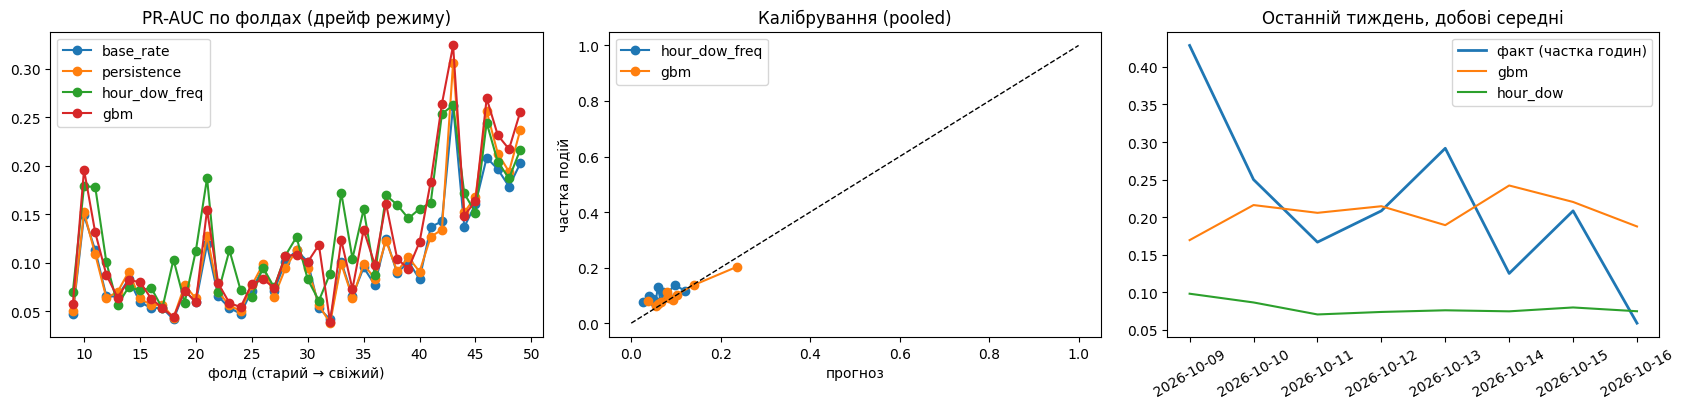

,model,n,prevalence,brier,bss_vs_base_rate,pr_auc,roc_auc,recall@fpr5%,ece
0,base_rate,6888,0.1015,0.0921,0.0073,0.1501,0.6009,0.1047,0.0354
1,persistence,6888,0.1015,0.0921,0.0072,0.1573,0.5972,0.1222,0.0377
2,hour_dow_freq,6888,0.1015,0.0924,0.0045,0.1136,0.5450,0.0501,0.0362
3,gbm,6888,0.1015,0.0911,0.0187,0.1488,0.5956,0.1161,0.0172


Бойовий прогноз: {'made_at': '2026-10-16 17:00:00+00:00', 'window': '(2026-10-16 17:00:00+00:00, 2026-10-16 18:00:00+00:00]', 'p_gbm': 0.20833333333333334, 'backend': 'lightgbm'}


In [51]:
from sklearn.calibration import calibration_curve
m, p = res["metrics"], res["preds"]
models = ["base_rate", "persistence", "hour_dow_freq", "gbm"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

for name in models:
    d = m[m.model == name]
    ax[0].plot(d.fold, d["pr_auc"], marker="o", label=name)
ax[0].set(title="PR-AUC по фолдах (дрейф режиму)", xlabel="фолд (старий → свіжий)"); ax[0].legend()

for name in ["hour_dow_freq", "gbm"]:
    fr, mp = calibration_curve(p["y"], p[name], n_bins=10, strategy="quantile")
    ax[1].plot(mp, fr, marker="o", label=name)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(title="Калібрування (pooled)", xlabel="прогноз", ylabel="частка подій"); ax[1].legend()

last = p[p.fold == p.fold.max()].set_index("t")
daily = last[["y", "gbm", "hour_dow_freq"]].resample("D").mean()
ax[2].plot(daily.index, daily["y"], label="факт (частка годин)", lw=2)
ax[2].plot(daily.index, daily["gbm"], label="gbm"); ax[2].plot(daily.index, daily["hour_dow_freq"], label="hour_dow")
ax[2].set(title="Останній тиждень, добові середні"); ax[2].legend(); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

display(res["pooled"].round(4))
print("Бойовий прогноз:", res["forecast"])